In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('netflix_titles.csv')

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (8807, 12)

Column Names:
Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [7]:
# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [8]:
# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (8807, 12)


In [10]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

director        29.908028
country          9.435676
cast             9.367549
date_added       0.113546
rating           0.045418
duration         0.034064
show_id          0.000000
type             0.000000
title            0.000000
release_year     0.000000
listed_in        0.000000
description      0.000000
dtype: float64


In [11]:
# Fill missing values

df['director'] = df['director'].fillna('Unknown')

df['cast'] = df['cast'].fillna('Unknown')

df['country'] = df['country'].fillna('Unknown')

df['rating'] = df['rating'].fillna(df['rating'].mode()[0])

df['date_added'] = df['date_added'].fillna('Not Available')

df['duration'] = df['duration'].fillna('Not Available')

print("Missing values handled successfully!")

Missing values handled successfully!


In [12]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [13]:
# Count Movies and TV Shows

print(df['type'].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


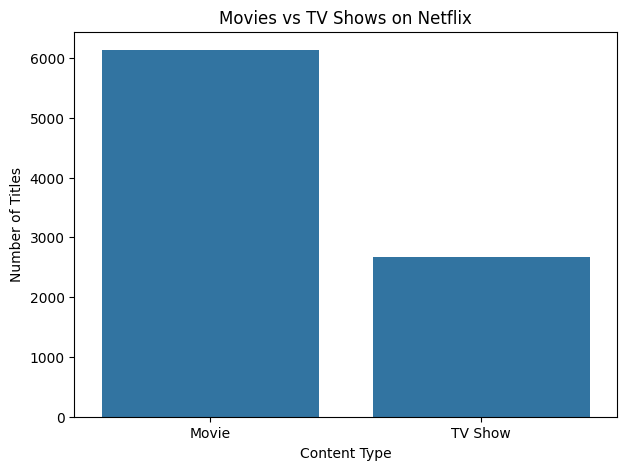

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='type')

plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()

In [15]:
# Count content ratings

print(df['rating'].value_counts())

rating
TV-MA       3211
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


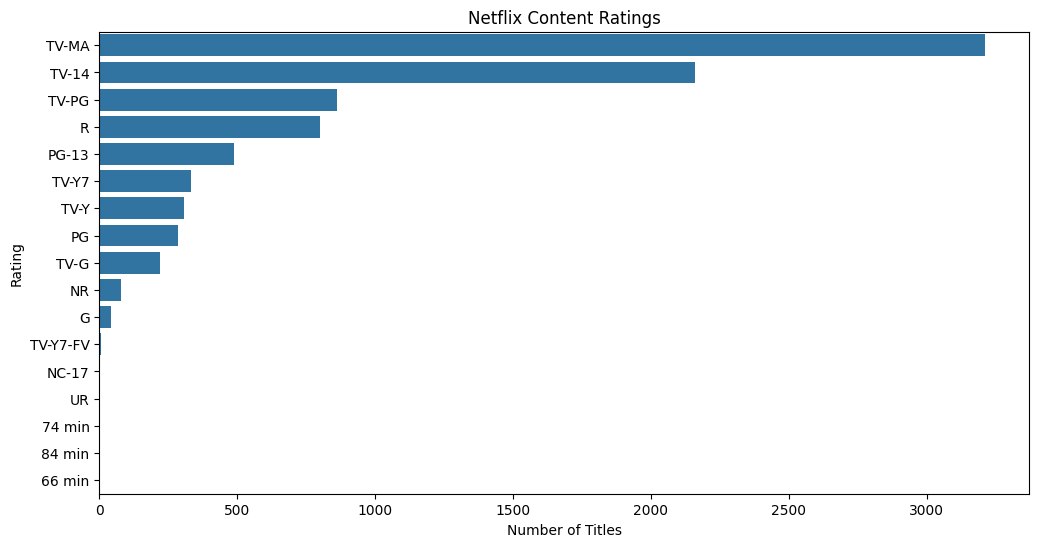

In [16]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)

plt.title('Netflix Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Rating')

plt.show()

In [17]:
# Top 10 countries

top_countries = df['country'].str.split(', ').explode()

top_countries = top_countries[top_countries != 'Unknown']

print(top_countries.value_counts().head(10))

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


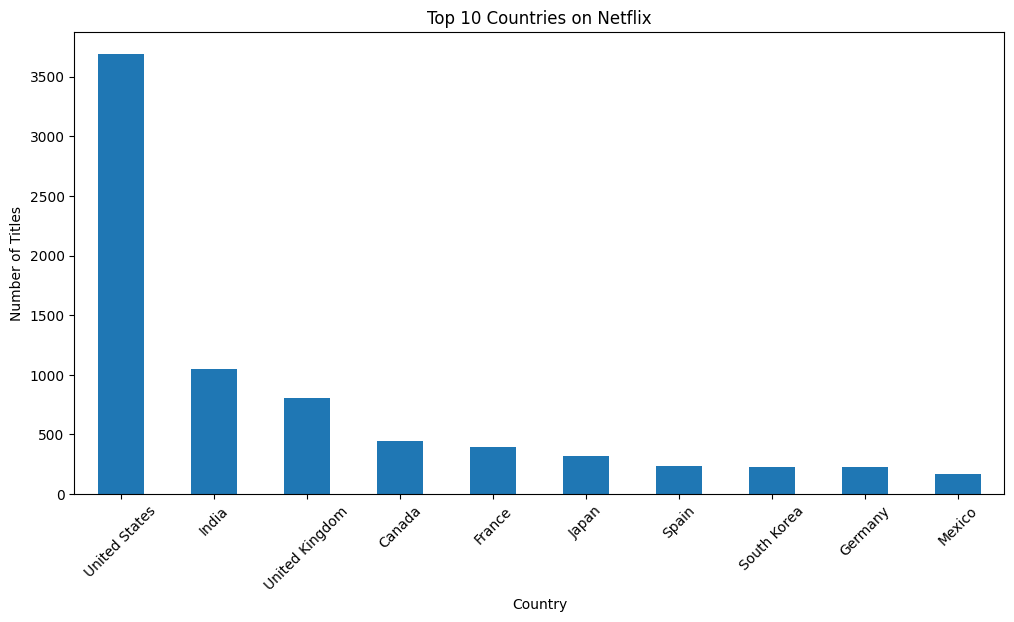

In [18]:
plt.figure(figsize=(12,6))

top_countries.value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Countries on Netflix')
plt.xlabel('Country')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.show()

In [19]:
# Count content by release year

yearly_content = df['release_year'].value_counts().sort_index()

print(yearly_content.tail(20))

release_year
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


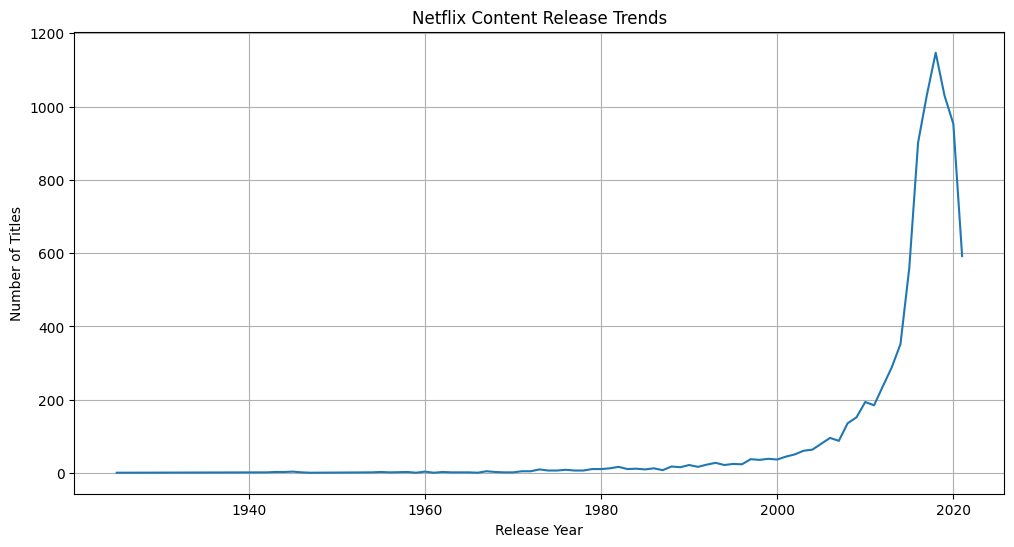

In [20]:
plt.figure(figsize=(12,6))

yearly_content.plot(kind='line')

plt.title('Netflix Content Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True)

plt.show()

In [21]:
# Analyze Netflix genres

genres = df['listed_in'].str.split(', ').explode()

top_genres = genres.value_counts().head(10)

print("Top 10 Netflix Genres:")
print(top_genres)

Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


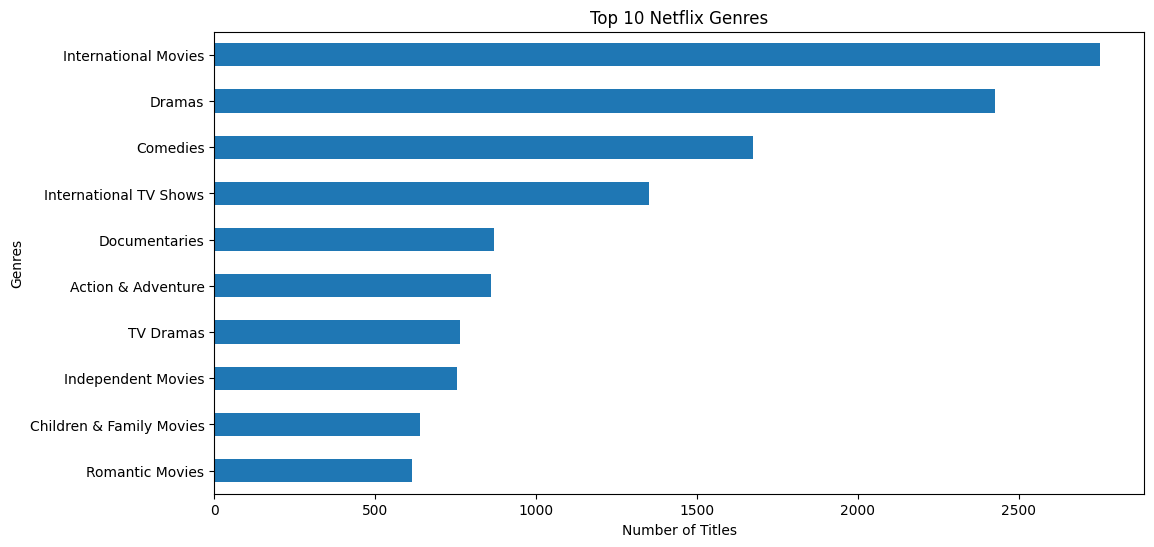

In [22]:
plt.figure(figsize=(12,6))

top_genres.sort_values().plot(kind='barh')

plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genres')

plt.show()

In [23]:
# Movies and TV Shows by release year

content_by_year = df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

print(content_by_year.tail(15))

type          Movie  TV Show
release_year                
2007             74       14
2008            113       23
2009            118       34
2010            154       40
2011            145       40
2012            173       64
2013            225       63
2014            264       88
2015            398      162
2016            658      244
2017            767      265
2018            767      380
2019            633      397
2020            517      436
2021            277      315


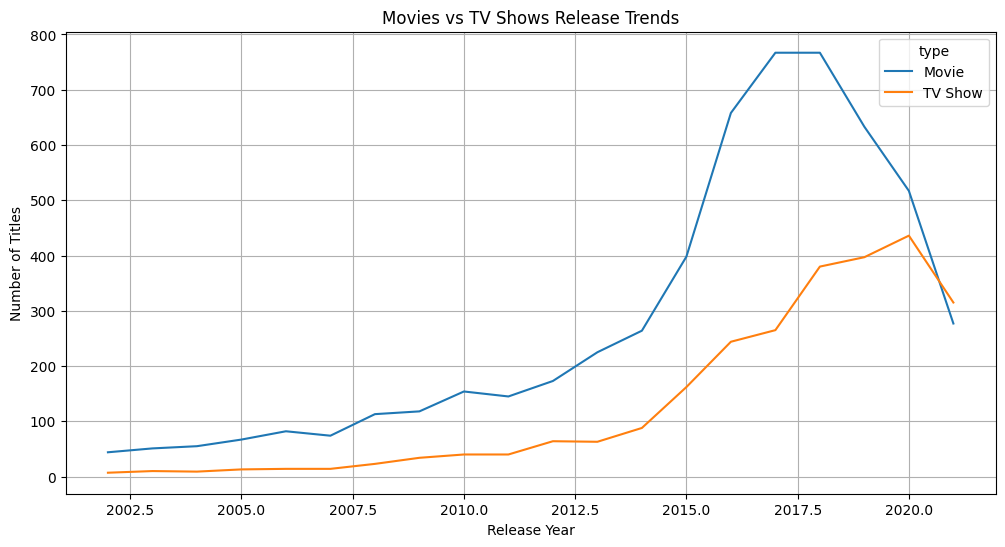

In [24]:
content_by_year.tail(20).plot(
    kind='line',
    figsize=(12,6)
)

plt.title('Movies vs TV Shows Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True)
plt.show()

In [25]:
# Filter only movies
movies = df[df['type'] == 'Movie'].copy()

# Extract duration in minutes
movies['duration_minutes'] = (
    movies['duration'].str.extract(r'(\d+)').astype(float)
)

print("Movie Duration Analysis:")
print(movies['duration_minutes'].describe())

Movie Duration Analysis:
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


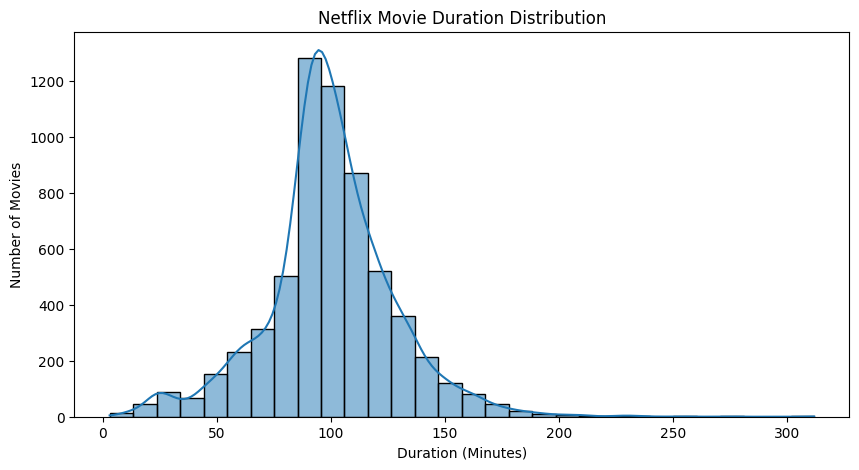

In [26]:
plt.figure(figsize=(10,5))

sns.histplot(
    movies['duration_minutes'].dropna(),
    bins=30,
    kde=True
)

plt.title('Netflix Movie Duration Distribution')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')

plt.show()

In [27]:
# Filter only TV Shows

tv_shows = df[df['type'] == 'TV Show'].copy()

# Extract number of seasons

tv_shows['seasons'] = (
    tv_shows['duration'].str.extract(r'(\d+)').astype(float)
)

print("TV Show Seasons Analysis:")
print(tv_shows['seasons'].describe())

TV Show Seasons Analysis:
count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: seasons, dtype: float64


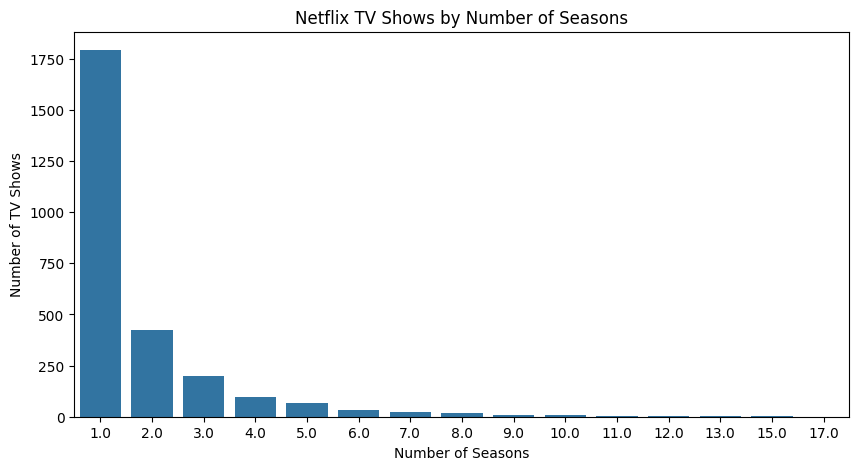

In [29]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=tv_shows,
    x='seasons',
    order=sorted(tv_shows['seasons'].dropna().unique())
)

plt.title('Netflix TV Shows by Number of Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')

plt.show()

In [30]:
# Top 10 Directors

directors = df['director'].str.split(', ').explode()

directors = directors[directors != 'Unknown']

top_directors = directors.value_counts().head(10)

print("Top 10 Directors on Netflix:")
print(top_directors)

Top 10 Directors on Netflix:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Martin Scorsese        12
Youssef Chahine        12
Jay Chapman            12
Name: count, dtype: int64


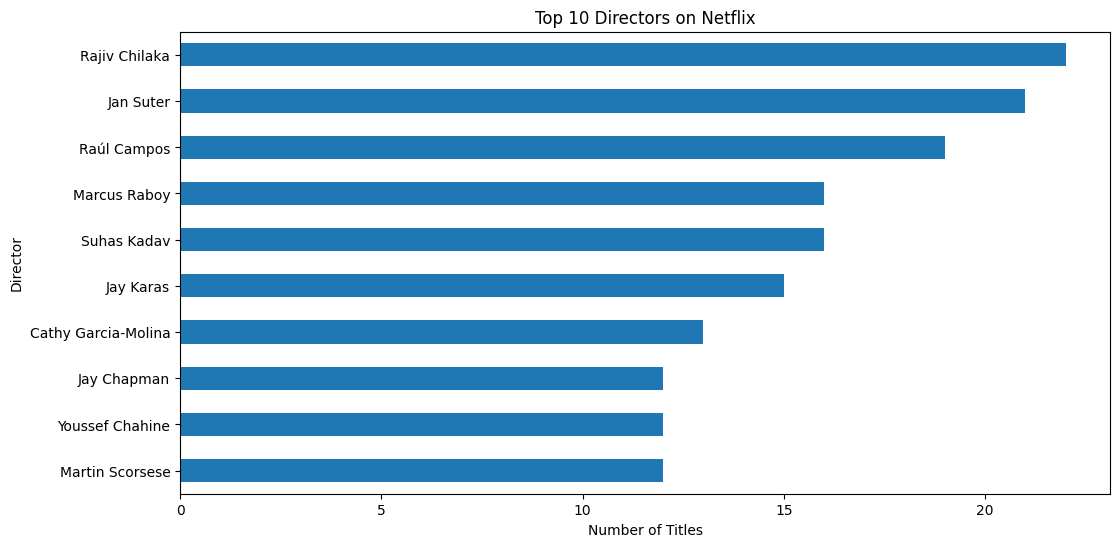

In [31]:
plt.figure(figsize=(12,6))

top_directors.sort_values().plot(kind='barh')

plt.title('Top 10 Directors on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Director')

plt.show()

In [32]:
# Convert date_added into datetime format

df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    format='mixed',
    errors='coerce'
)

print("Date conversion completed!")

Date conversion completed!


In [33]:
# Extract year from date_added

df['year_added'] = df['date_added'].dt.year

yearly_added = df['year_added'].value_counts().sort_index()

print("Netflix Content Added by Year:")
print(yearly_added)

Netflix Content Added by Year:
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


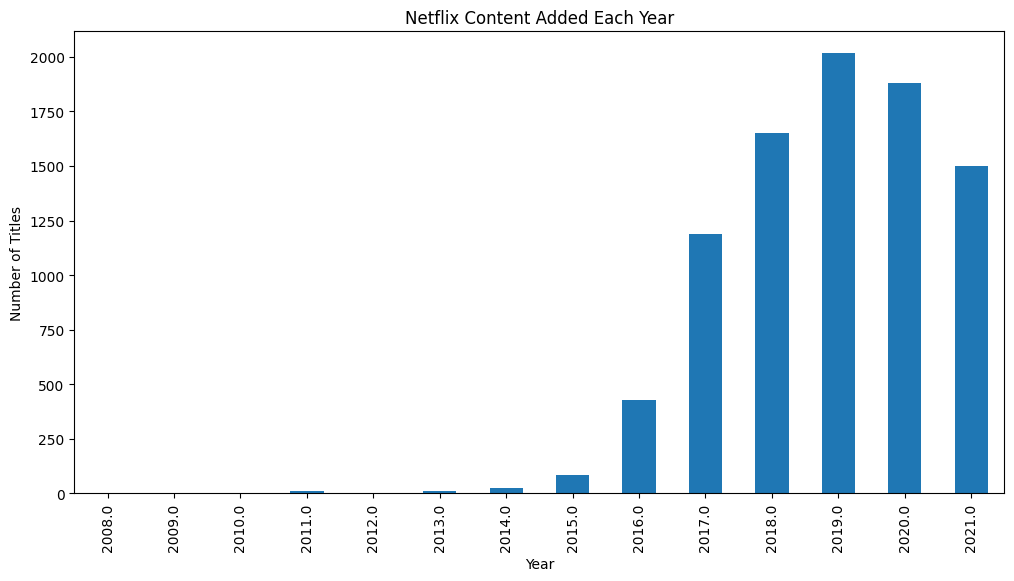

In [34]:
plt.figure(figsize=(12,6))

yearly_added.plot(kind='bar')

plt.title('Netflix Content Added Each Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')

plt.show()

In [35]:
print("========== NETFLIX DATA ANALYSIS ==========")

print("\nTotal Titles:", len(df))

print("\nMovies:", (df['type'] == 'Movie').sum())

print("\nTV Shows:", (df['type'] == 'TV Show').sum())

print("\nMost Common Rating:")
print(df['rating'].mode()[0])

print("\nTop 5 Genres:")
print(top_genres.head())

print("\nTop 5 Countries:")
print(top_countries.value_counts().head())

print("\nMost Common Release Year:")
print(df['release_year'].mode()[0])

========== NETFLIX DATA ANALYSIS ==========

Total Titles: 8807

Movies: 6131

TV Shows: 2676

Most Common Rating:
TV-MA

Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

Top 5 Countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

Most Common Release Year:
2018


In [36]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Final Dataset Shape: (8807, 13)

Missing Values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
year_added      10
dtype: int64

Duplicate Records: 0


In [37]:
df.to_csv('Netflix_Cleaned_Dataset.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
